### Get data

In [276]:
import numpy as np
import pandas as pd

#### Rod

In [277]:
l = 1.05
sigma_l = 1

In [278]:
d = np.array([0.47, 0.37, 0.27, 0.17, 0.07, 0.02, 0.12, 0.22, 0.32, 0.42])
sigma_d = np.full(d.shape, 0.01)

buchi: 10,20,30,...
cm: 52.5

In [279]:
d

array([0.47, 0.37, 0.27, 0.17, 0.07, 0.02, 0.12, 0.22, 0.32, 0.42])

#### Period

15.89, 16.00, 15.89, 15.93, 15.86  
first buco

[16.35, 16.15, 16.27, 16.34, 16.16]

[16.35, 16.36, 16.38, 16.34, 16.36]

In [280]:
T_full = np.array([[16.35, 16.36, 16.38, 16.34, 16.36],
              [15.72, 15.71, 15.62, 15.64, 15.69],
              [15.55, 15.48, 15.53, 15.59, 15.67],
              [16.87, 16.44, 16.68, 16.54, 16.84],
              [22.81, 22.59, 22.59, 22.70, 22.76],
              [38.23, 38.82, 38.73, 38.99, 38.83],
              [18.57, 18.83, 18.67, 18.90, 18.79],
              [15.93, 15.76, 15.87, 15.94, 15.72],
              [15.73, 15.54, 15.47, 15.57, 15.65],
              [16.03, 15.97, 16.13, 16.19, 16.03]
              ])  

In [281]:
#T_full = np.array([[15.96, 16.05, 16.04, 15.92, 15.94],
#                   [15.57, 15.64, 15.55, 15.50, 15.49],
#                   [16.03, 15.81, 15.86, ]
#              ])  


# each row are all measurements with a specific length d
# each row, not each col

### Data analysis

better

In [282]:
T = np.mean(T_full, axis=1)/10
sigma_T = np.std(T_full/10, ddof=1, axis=1)

In [283]:
for x in range(len(T_full)):
    print(f'd: {d[x]:.2f}, T = {T[x]:.2f} + {sigma_T[x]:.2f}')

d: 0.47, T = 1.64 + 0.00
d: 0.37, T = 1.57 + 0.00
d: 0.27, T = 1.56 + 0.01
d: 0.17, T = 1.67 + 0.02
d: 0.07, T = 2.27 + 0.01
d: 0.02, T = 3.87 + 0.03
d: 0.12, T = 1.88 + 0.01
d: 0.22, T = 1.58 + 0.01
d: 0.32, T = 1.56 + 0.01
d: 0.42, T = 1.61 + 0.01


In [284]:
T

array([1.6358, 1.5676, 1.5564, 1.6674, 2.269 , 3.872 , 1.8752, 1.5844,
       1.5592, 1.607 ])

### Plot

i have:   

d  
sigma_d  
T  
sigma_T  

In [285]:
def period_model(d, l):
    return 2.0 * np.pi * np.sqrt((l**2.0 / 12.0 + d**2.0) / (9.81 * d))

In [286]:
x = d
y = T  
sigma_x = sigma_d
sigma_y = sigma_T*10  
model = period_model

In [287]:
x

array([0.47, 0.37, 0.27, 0.17, 0.07, 0.02, 0.12, 0.22, 0.32, 0.42])

In [288]:
l

1.05

In [289]:
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit

fitted l = 1.0277471499840807 + 0.010166250165264736


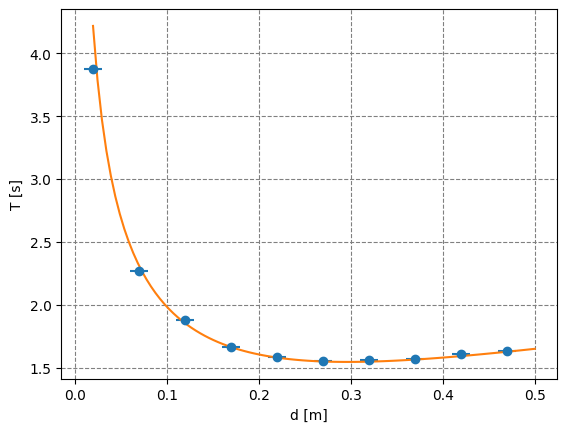

In [290]:
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit


plt.figure('Periodo')
plt.errorbar(d, T, sigma_T, sigma_d, fmt='o')

popt, pcov = curve_fit(period_model, d, T, sigma=sigma_T)
l_hat = popt[0]
sigma_l = np.sqrt(pcov[0, 0])

print(f'fitted l = {l_hat} + {sigma_l}')


t = np.linspace(0.02, 0.5, 100)
plt.plot(t, period_model(t, l_hat))
plt.xlabel('d [m]')
plt.ylabel('T [s]')
plt.grid(which='both', ls='dashed', color='gray')

plt.show()

In [291]:
res = y - period_model(x, *popt)


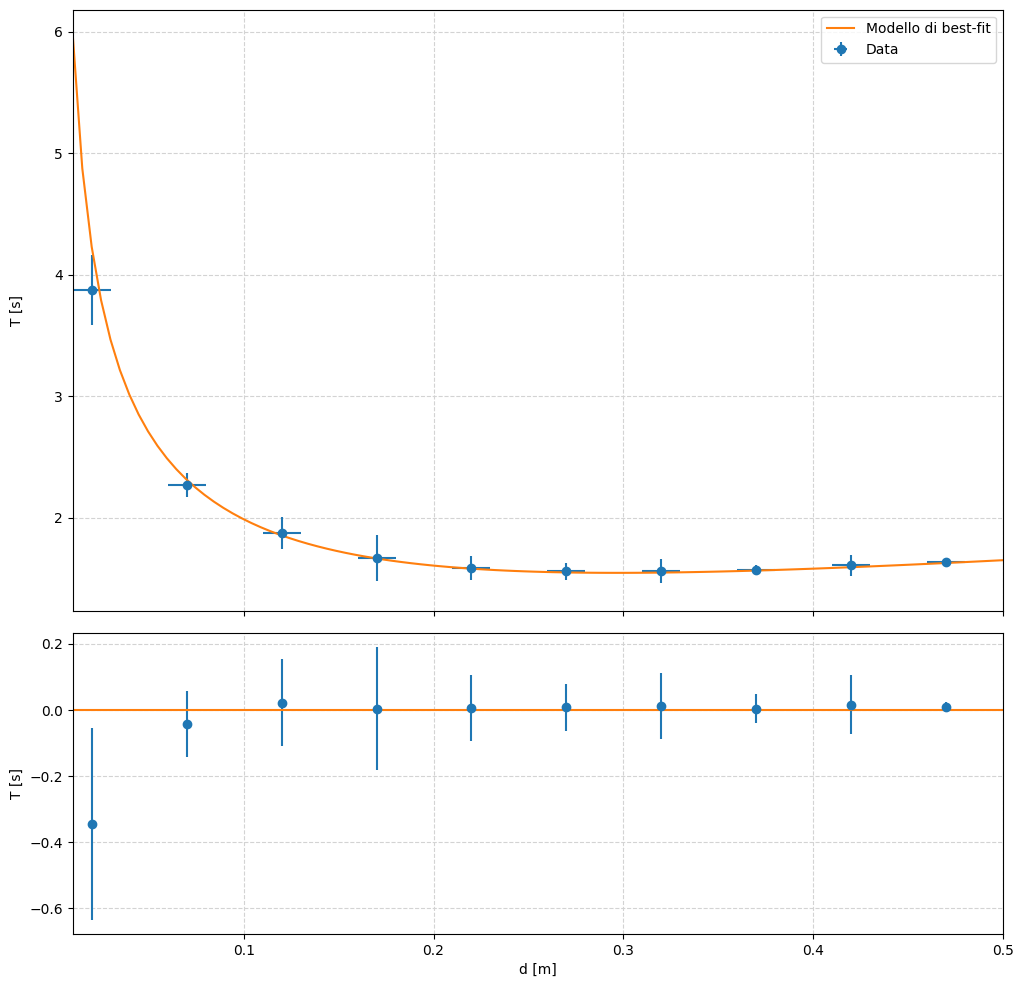

In [292]:
# Fit
popt, pcov = curve_fit(model, x, y, sigma=sigma_y)
res = y - model(x, *popt)

# Create the main figure
fig = plt.figure(figsize=(12, 12))
ax1, ax2 = fig.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))
xgrid = np.linspace(0.01, 0.5, 100)

# Main plot: the scatter plot of x vs. y, on the top panel.
ax1.errorbar(x, y, xerr=sigma_x, yerr=sigma_y, fmt='o', label='Data')
ax1.plot(xgrid, model(xgrid, popt[0]), label='Modello di best-fit')

# And now the residual plot, on the bottom panel.
ax2.errorbar(x, res, sigma_y, fmt='o')
ax2.plot(xgrid, np.full(xgrid.shape, 0.0)) # horizontal line at y=0

# STYLING  

ax1.set_ylabel('T [s]')
ax1.grid(color='lightgray', ls='dashed')
ax1.legend()

ax2.set_xlabel('d [m]')
ax2.set_ylabel('T [s]')
ax2.grid(color='lightgray', ls='dashed')

plt.xlim(0.01, 0.5)
fig.align_ylabels((ax1, ax2))

plt.show()

fitted l = 1.0277471499840807 + 0.010166250165264736


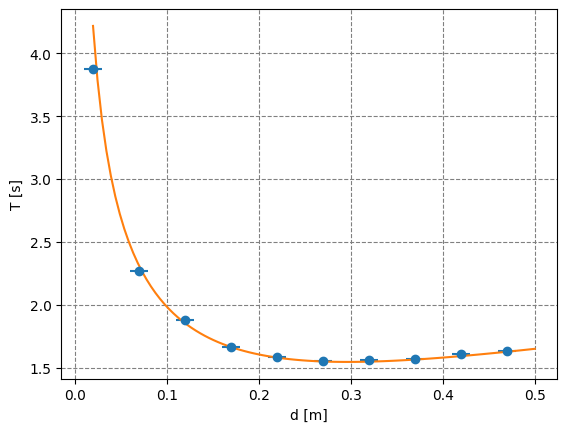

In [293]:
plt.figure('Periodo')
plt.errorbar(d, T, sigma_T, sigma_d, fmt='o')

popt, pcov = curve_fit(period_model, d, T, sigma=sigma_T)
l_hat = popt[0]
sigma_l = np.sqrt(pcov[0, 0])

print(f'fitted l = {l_hat} + {sigma_l}')


x = np.linspace(0.02, 0.5, 100)
plt.plot(x, period_model(x, l_hat))
plt.xlabel('d [m]')
plt.ylabel('T [s]')
plt.grid(which='both', ls='dashed', color='gray')

plt.show()

In [294]:
print(f'Parameters: {popt}')
print(f'Errors: {np.sqrt(np.diag(pcov))}')

Parameters: [1.02774715]
Errors: [0.01016625]


In [295]:
chisq = np.sum((res / sigma_y)**2)
dof = len(y) - len(popt)
chi2_red = chisq / dof  # must give 1  

print(f'Chi: {chisq}')
print(f'Dof: {dof}')
print(f'Chi reduced: {chi2_red}')

Chi: 2.1059653553715396
Dof: 9
Chi reduced: 0.23399615059683773


### Notes

obiettivo, vedere se l che viene dalla formula conicide con quello vero  

compatibilità

$ | \hat{a} - \hat{b} | \le n\sqrt{\sigma^2_a+ \sigma^2_b }$  


In [296]:
left = abs(1.05-1.040)

In [297]:
import math
right= math.sqrt(0.01**2 + 0.003**2)

In [298]:
print(left, right)

0.010000000000000009 0.01044030650891055
